# 01: Exploratory data analysis

FlowCast, Northline Corridor. Everything here calls `src/eda.py` on the cleaned dataset, leaving out estimated rows. The last section lists the findings that drove modelling choices.

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src import eda
from src.clean import load_dataset
from src.features import load_features
from src.utils import load_config, project_path

sns.set_theme(style="whitegrid", context="notebook")
cfg = load_config()
FIGURES = project_path("figures", cfg)
df = load_dataset(cfg)
features = load_features(1, cfg)
print(f"{len(df):,} rows, {df['road_id'].nunique()} segments, {df['ts'].min():%d %b %Y} to {df['ts'].max():%d %b %Y}")


181,200 rows, 25 segments, 01 Jan 2025 to 31 May 2025


## Distributions

Volume is right-skewed (skew 1.0) with a long peak-hour tail, and speed is left-skewed (skew -1.0) because congestion pulls it down. Rainfall and visibility are dominated by a dry, clear mode, so rare weather needs its own flags.

,mean,median,std,min,max,skew,p01,p99
traffic_volume,431.45,362.00,283.56,41.0,2090.00,1.00,83.00,1234.00
avg_speed,42.10,44.90,11.39,6.7,64.80,-1.01,8.40,57.70
occupancy,31.17,27.00,19.60,3.0,100.00,0.83,6.20,83.20
travel_time,3.57,3.12,2.53,0.8,29.91,3.65,0.96,14.96
temperature,17.97,18.00,4.37,5.8,29.80,-0.00,9.00,26.90
rainfall,0.19,0.00,1.06,0.0,8.90,6.02,0.00,7.00
visibility,9673.15,10000.00,1499.10,301.0,10000.00,-4.55,2061.00,10000.00


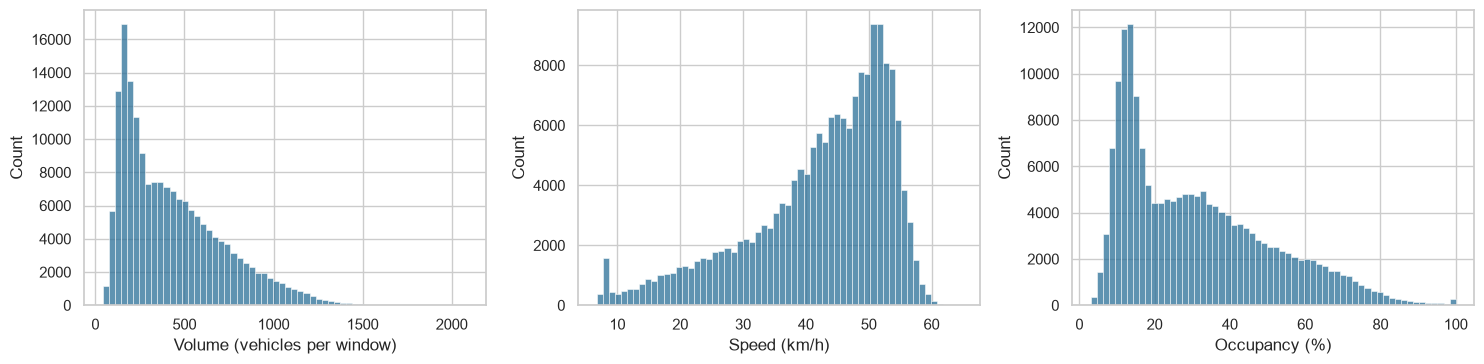

In [2]:
display(eda.distribution_summary(df))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
rows = eda.observed(df)
for ax, col, label in zip(axes, ["traffic_volume", "avg_speed", "occupancy"], ["Volume (vehicles per window)", "Speed (km/h)", "Occupancy (%)"]):
    sns.histplot(rows[col], bins=60, ax=ax, color="#2a6f97")
    ax.set_xlabel(label)
fig.tight_layout(); fig.savefig(FIGURES / "eda_distributions.png", dpi=120); plt.show()

## Daily and weekly profiles

Weekdays have a sharp morning peak at 08:30 and a broader evening peak around 18:00. Speed mirrors volume. This checks the configured peak windows (07:30-10:00, 17:00-20:00).

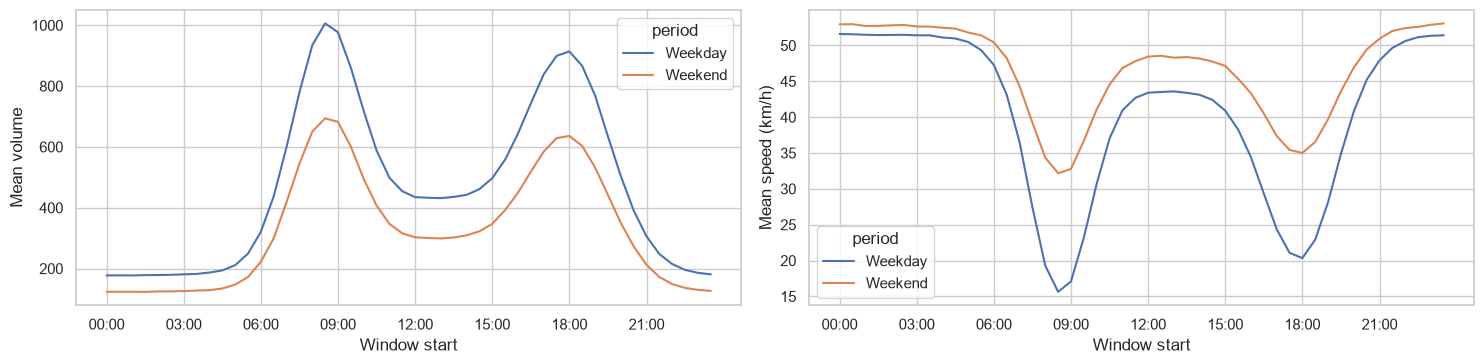

,period,time,traffic_volume,avg_speed,occupancy
17,Weekday,08:30,1005.89,15.63,72.37
18,Weekday,09:00,976.88,17.09,70.08
16,Weekday,08:00,934.23,19.29,67.32
36,Weekday,18:00,913.86,20.34,65.76
35,Weekday,17:30,899.09,21.07,64.87


In [3]:
profile = eda.daily_profile(df)
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for ax, col, label in zip(axes, ["traffic_volume", "avg_speed"], ["Mean volume", "Mean speed (km/h)"]):
    sns.lineplot(profile, x="time", y=col, hue="period", ax=ax)
    ax.set_xticks(ax.get_xticks()[::6]); ax.set_ylabel(label); ax.set_xlabel("Window start")
fig.tight_layout(); fig.savefig(FIGURES / "eda_daily_profile.png", dpi=120); plt.show()
display(profile[profile.period == "Weekday"].nlargest(5, "traffic_volume"))

## Correlation and multicollinearity

The correlation matrix comes from the from-scratch covariance in `src/scratch.py`. Volume, speed and occupancy are nearly interchangeable (|r| of about 0.9). VIF is the diagonal of the inverse correlation matrix.

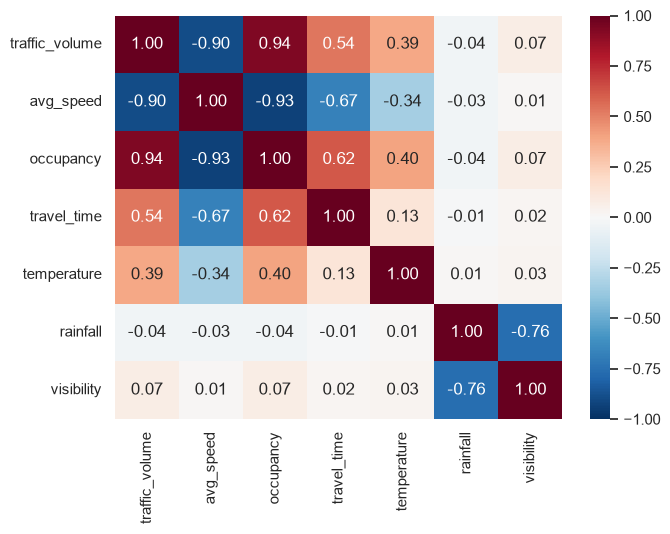

,feature,vif
0,vol_mean4,281.6
1,vc_t,60.9
2,vol_t2,58.1
3,vol_t1,45.4
4,occ_t,43.4
5,vol_t,39.2
6,vol_mean8,15.4
7,speed_t,9.1
8,vol_week,5.2
9,vol_day,4.5


In [4]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(eda.correlation_table(df), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
fig.tight_layout(); fig.savefig(FIGURES / "eda_correlation.png", dpi=120); plt.show()
display(eda.vif_table(features))

## Weather

Compared within peak and off-peak hours, so the clock doesn't confound the result. Note how few fog windows there are at peak (62).

,period,weather_condition,windows,volume,speed,visibility,accident_rate_pct
0,Off-peak,Clear,102112,329.58,46.70,9996.90,0.63
1,Off-peak,Cloudy,27424,322.88,46.99,9997.63,0.63
2,Off-peak,Fog,1186,202.71,45.88,723.54,3.46
3,Off-peak,Rain,5467,293.21,43.07,3379.12,3.55
4,Peak,Clear,30603,797.26,26.61,9998.82,1.47
5,Peak,Cloudy,8355,777.37,27.72,10000.00,1.16
6,Peak,Fog,62,519.50,35.27,899.40,4.84
7,Peak,Rain,1492,642.87,29.82,3583.29,3.15


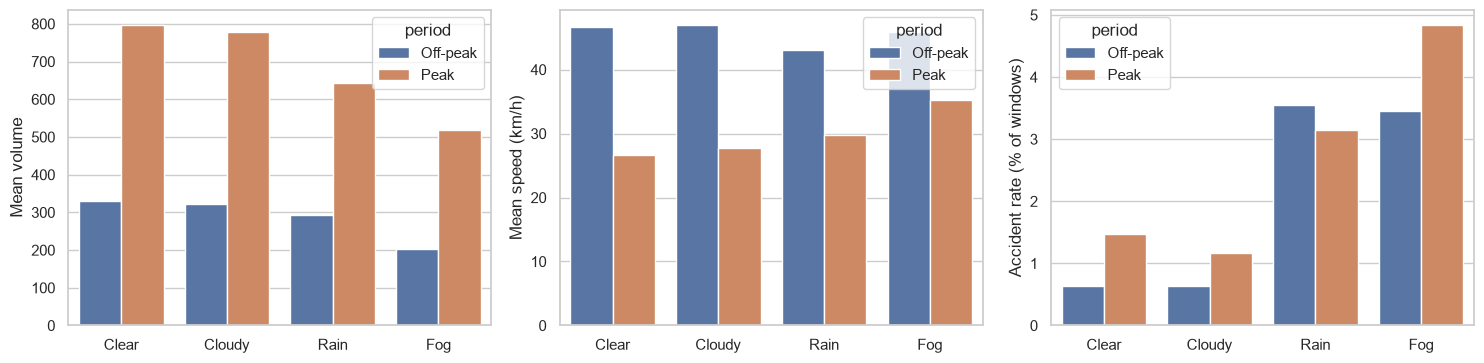

In [5]:
weather = eda.weather_effects(df)
display(weather)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, label in zip(axes, ["volume", "speed", "accident_rate_pct"], ["Mean volume", "Mean speed (km/h)", "Accident rate (% of windows)"]):
    sns.barplot(weather, x="weather_condition", y=col, hue="period", ax=ax, order=cfg["weather"]["vocabulary"])
    ax.set_ylabel(label); ax.set_xlabel("")
fig.tight_layout(); fig.savefig(FIGURES / "eda_weather.png", dpi=120); plt.show()

## Holidays, events and roadworks

Weekdays only. These effects are large but rest on very few days, so they can only be used as flags.

In [6]:
display(eda.calendar_effects(df))

,day_type,days,volume,speed,accident_rate_pct
0,Event,5,646.74,33.79,1.40
1,Holiday,2,262.79,49.25,0.51
2,Ordinary,92,480.73,40.72,1.02
3,Roadwork,9,336.41,38.19,0.69


## Accidents

The base rate is under 1% of windows. The tables below show which conditions raise it. `accident_autocorrelation` compares the rate after a recent accident with the base rate (lag 0).

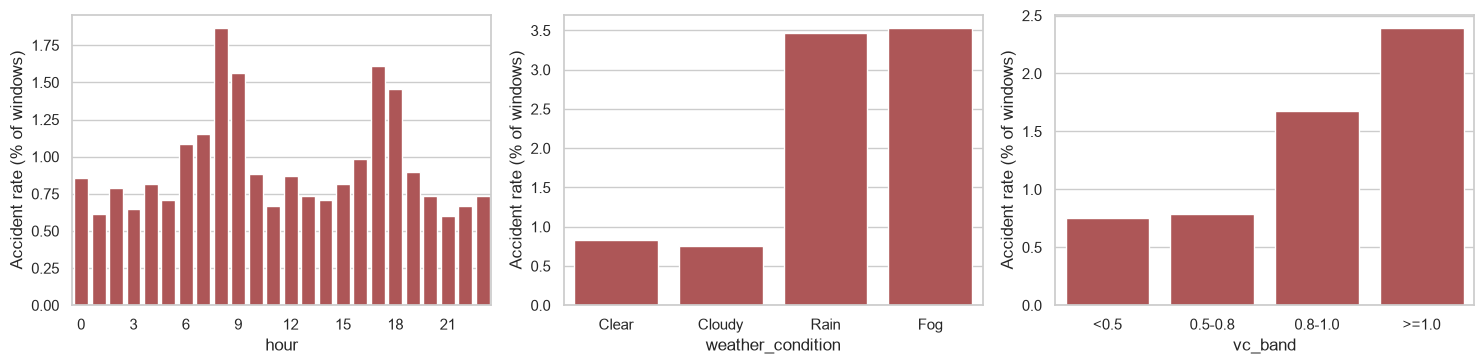

,segment accident rate (%)
count,25.000
mean,0.935
std,0.139
min,0.666
25%,0.821
50%,0.920
75%,1.050
max,1.191


,lag_windows,accident_rate_pct
0,0,0.912
1,1,1.634
2,2,1.151
3,4,1.090
4,48,0.737


In [7]:
accidents = eda.accident_profile(df)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.barplot(accidents["hour"], x="hour", y="accident_rate_pct", ax=axes[0], color="#bc4749"); axes[0].set_xticks(range(0, 24, 3))
sns.barplot(accidents["weather"], x="weather_condition", y="accident_rate_pct", ax=axes[1], color="#bc4749", order=cfg["weather"]["vocabulary"])
sns.barplot(accidents["vc_band"], x="vc_band", y="accident_rate_pct", ax=axes[2], color="#bc4749")
for ax in axes: ax.set_ylabel("Accident rate (% of windows)")
fig.tight_layout(); fig.savefig(FIGURES / "eda_accidents.png", dpi=120); plt.show()
display(accidents["segment"]["accident_rate_pct"].describe().round(3).to_frame("segment accident rate (%)"))
display(eda.accident_autocorrelation(df))

## Residuals of a naive forecast

The z-score outlier rule assumes readings that are roughly normal, and regression metrics behave best with even error spread. This looks at the seasonal-naive residual on training dates.

,value
mean,1.69
std,146.41
skew,0.03
excess_kurtosis,5.53
share_beyond_3_sigma_pct,2.06
std_peak,233.79
std_off_peak,107.45


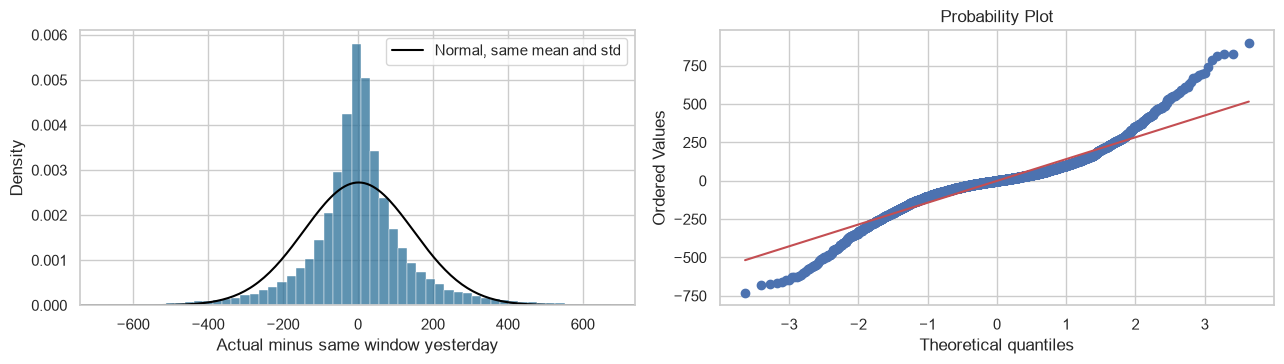

In [8]:
rows = features[(features.split == "train") & features.target_valid]
residual = rows.y_volume - rows.vol_day
display(pd.Series(eda.naive_residuals(features)).round(2).to_frame("value"))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(residual, bins=100, ax=axes[0], stat="density", color="#2a6f97")
grid = np.linspace(residual.quantile(0.001), residual.quantile(0.999), 200)
axes[0].plot(grid, stats.norm.pdf(grid, residual.mean(), residual.std()), color="black", label="Normal, same mean and std"); axes[0].legend()
axes[0].set_xlim(grid[0], grid[-1]); axes[0].set_xlabel("Actual minus same window yesterday")
stats.probplot(residual.sample(5000, random_state=cfg["seed"]), plot=axes[1])
fig.tight_layout(); fig.savefig(FIGURES / "eda_residuals.png", dpi=120); plt.show()

## How much segments move together, and the baselines to beat

Coupling is the median correlation between segments' volume residuals after removing each segment's own window x weekday profile.

In [9]:
print(f"Median between-segment residual correlation: {eda.segment_coupling(df):.3f}")
display(eda.baseline_scores(features))

Median between-segment residual correlation: 0.635


,baseline,rmse,mape_pct
0,Persistence (t),101.99,16.17
1,Same window yesterday,138.89,23.29
2,Same window last week,123.01,19.21


## Findings that drive the modelling

1. **Recent values beat seasonal ones.** On validation dates, persistence (RMSE 102, MAPE 16.2%) beats last week (123, 19.2%) and yesterday (139, 23.3%). Lags at t, t-1 and t-2 and the short rolling means should rank highest. These baselines are what every model must beat, and even persistence misses the 12% MAPE target.
2. **Short-term volume features are heavily collinear.** VIF reaches 282 (`vol_mean4`), and is above 40 for the recent lags, V/C and occupancy. That does not hurt prediction, so they stay. It does mean linear coefficients can't be read one at a time, and importance will be shared among them, so the report uses permutation importance on groups of features rather than single coefficients.
3. **Errors are not constant or normal.** The naive residual's spread is more than twice as wide at peak (std 234) as off-peak (107), with excess kurtosis 5.5. This justifies computing the conformal bands separately for peak and off-peak (D12) rather than one width everywhere, and the error breakdowns by hour.
4. **Weather shifts demand more than it slows traffic.** Rain cuts volume by 11% off-peak and 19% at peak; fog by 38% and 35%. Off-peak speed falls about 8% in rain but only about 2% in fog, so **the working hypothesis that fog lowers speed more than rain was wrong**. At peak, speed is actually higher in rain and fog than in clear weather, because lower demand outweighs the slower conditions. Peak fog rests on only 62 windows.
5. **Calendar effects are large but thinly evidenced.** On weekdays, compared with ordinary days, volume is about 45% lower on holidays (2 days), 35% higher on event days (5 days) and 30% lower on roadwork days (9 days). They're used as flags and peak interactions, and the report notes how few days support them.
6. **Accident risk has real but modest signal.** The rate is about 4x higher in rain or fog (about 3.5% against 0.8%), about 3x higher at V/C >= 1 (2.4% against 0.75%), and higher at the morning peak. It varies little by segment (0.67-1.19%). A recent accident raises the next window's rate from 0.91% to 1.63%, and this fades within about two windows. So `accidents_last4`, weather and interaction features are justified. But the target-hour weather isn't known at issue time, which limits what a model can reach: the ROC-AUC >= 0.75 target remains the riskiest.
7. **Congestion is imbalanced and rule-based.** Free-flow 61%, Moderate 24%, Heavy 9%, Severe 5%. The label is a fixed function of volume, so regress-then-band is a strong candidate, and direct classifiers need class weights.
8. **Segments move together.** The median residual correlation between segments is 0.64, even after removing each segment's own profile, which points to shared corridor-wide day effects. One global model across all segments is therefore well justified, for both the classical and deep models.
